# Indirect Estimation of Train-Test Drug Overlap via Feature Space Distances
Does the test set share drugs with train? Indirect estimation from feature space distances

The test set has no `drug_id`, so the question cannot be directly verified. This notebook addresses it indirectly, **without GPUs and without models**:

1. **Configuration and utilities:** Search input directories, set hyper-parameters, load drug mappings, and initialize the random number generator.
2. **Data loading and feature representation:** Filter out control samples (`ctl_vehicle`), build standardized and L2-normalized gene ($g$-) and cell ($c$-) feature embeddings, and verify experimental design balance (`cp_time`, `cp_dose`).
3. **Nearest neighbor search and reference pools:** Split training data into row-wise (seen) and drug-grouped (unseen) reference folds, compute nearest-neighbor cosine distance (`d1`) using equal-sized pools, and calculate test set distances.
4. **Separability assessment (AUC & ECDF):** Evaluate how well nearest-neighbor distance separates seen vs. unseen reference distributions using quantiles, ROC-AUC, and empirical CDF plots.
5. **Estimation of $p$ via cluster bootstrap:** Estimate $p$ (proportion of test set rows with seen drugs) by fitting test set distances to a mixture $p \cdot F_{\text{seen}} + (1-p) \cdot F_{\text{unseen}}$ via least squares, with drug-level cluster bootstrap for 95% confidence intervals.
6. **Recovery check on pseudo-test sets:** Validate the method's bias and standard deviation by attempting to recover known values of $p$ on synthetic test sets created from holdout validation folds.
7. **Targeted analysis on highly frequent drugs:** Assign test set rows to highly frequent train drugs and compare observed counts against expected numbers under "absent" vs. "train-frequency" hypotheses.
8. **Summary and final verdict:** Aggregate metrics (AUC, estimated $p$, maximum recovery error, and frequent drug assignments) to render a final verdict on test set drug overlap.

**Limitations:** Distance to the nearest neighbor is a proxy. Even *different* drugs with the same mechanism have similar signatures, so the separation between "seen" and "unseen" is partial. If AUC is low, the notebook indicates it and the estimate of `p` is non-informative.


In [1]:
# Step 1 - configuration and utilities
import os, glob, time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

DATA_DIR = None                  # None: search test_features.csv under /kaggle/input
OUTPUT_DIR = "/kaggle/working"
N_FOLDS = 5
SEED = 42
FREQUENT_MIN_ROWS = 18           # same as HYBRID_MIN_ROWS from training
N_GRID = 50                      # thresholds for comparing CDFs
N_BOOT = 500
N_PSEUDO_REPS = 20
CTL_LABEL = "ctl_vehicle"
CHUNK = 1000                     # rows per matrix product

def find_input_directory(file_name):
    matches = glob.glob(f"/kaggle/input/**/{file_name}", recursive=True)
    directories = sorted({os.path.dirname(p) for p in matches})
    if len(directories) != 1:
        raise FileNotFoundError(f"Expected a single folder with '{file_name}' under /kaggle/input, found {len(directories)}: {directories}")
    return directories[0]

if DATA_DIR is None:
    DATA_DIR = find_input_directory("test_features.csv")
drug_path = os.path.join(DATA_DIR, "train_drug.csv")
if not os.path.exists(drug_path):
    drug_path = os.path.join(find_input_directory("train_drug.csv"), "train_drug.csv")
rng = np.random.default_rng(SEED)
print("Data:", DATA_DIR, "| drug file:", drug_path)


Data: /kaggle/input/competitions/lish-moa | drug file: /kaggle/input/competitions/lish-moa/train_drug.csv


In [2]:
# Step 2 - load data (treated rows only) and build the representation
train = pd.read_csv(f"{DATA_DIR}/train_features.csv")
test = pd.read_csv(f"{DATA_DIR}/test_features.csv")
drug_map = pd.read_csv(drug_path).set_index("sig_id")["drug_id"]

train = train[train["cp_type"] != CTL_LABEL].reset_index(drop=True)
test = test[test["cp_type"] != CTL_LABEL].reset_index(drop=True)
drug_ids = train["sig_id"].map(drug_map)
assert drug_ids.notna().all(), "some train sig_ids are missing drug_id"

g_cols = [c for c in train.columns if c.startswith("g-")]
c_cols = [c for c in train.columns if c.startswith("c-")]
stats = {name: (train[cols].values.mean(0), train[cols].values.std(0) + 1e-8) for name, cols in (("g", g_cols), ("c", c_cols))}

def embed(df):
    """Each block is standardized using train statistics and normalized to L2 norm 1; then concatenated.
    The dot product between two rows equals (cosine_g + cosine_c) / 2: both blocks are weighted equally."""
    blocks = []
    for name, cols in (("g", g_cols), ("c", c_cols)):
        mu, sd = stats[name]
        z = (df[cols].values - mu) / sd
        blocks.append(z / (np.linalg.norm(z, axis=1, keepdims=True) + 1e-12))
    return (np.hstack(blocks) / np.sqrt(2)).astype(np.float32)

X_train, X_test = embed(train), embed(test)
codes, drug_names = pd.factorize(drug_ids)
rows_per_drug = np.bincount(codes)
frequent_codes = np.where(rows_per_drug > FREQUENT_MIN_ROWS)[0]
n_train, n_test = len(X_train), len(X_test)
print(f"Train (treated): {n_train} rows, {len(drug_names)} drugs | test (treated): {n_test} rows")
print(f"Frequent drugs (> {FREQUENT_MIN_ROWS} rows): {len(frequent_codes)}, "
      f"{rows_per_drug[frequent_codes].sum() / n_train:.1%} of train rows")

# Distance also depends on the experimental design: check that train and test share the same mixture
for col in ("cp_time", "cp_dose"):
    mix = pd.DataFrame({"train": train[col].value_counts(normalize=True), "test": test[col].value_counts(normalize=True)}).round(3)
    print(f"\n{col}:\n{mix.to_string()}")


Train (treated): 21948 rows, 3288 drugs | test (treated): 3624 rows
Frequent drugs (> 18 rows): 9, 9.8% of train rows

cp_time:
         train   test
cp_time              
48       0.346  0.346
72       0.327  0.328
24       0.326  0.327

cp_dose:
         train   test
cp_dose              
D1        0.51  0.509
D2        0.49  0.491


In [3]:
# Step 3 - nearest neighbor, reference folds, and equal-sized pools
def nearest(Q, P):
    """Cosine distance (1 - similarity) from nearest neighbor in P and index of the neighbor."""
    d1 = np.empty(len(Q), dtype=np.float32); arg = np.empty(len(Q), dtype=np.int64)
    for s in range(0, len(Q), CHUNK):
        sim = Q[s:s + CHUNK] @ P.T
        a = sim.argmax(axis=1)
        arg[s:s + CHUNK] = a
        d1[s:s + CHUNK] = 1.0 - sim[np.arange(len(a)), a]
    return d1, arg

def random_folds(n, k):
    return np.array_split(rng.permutation(n), k)

def group_folds(group_codes, k):
    """Folds by drug (each drug in a single fold), balanced by number of rows using greedy allocation."""
    sizes = np.bincount(group_codes)
    order = rng.permutation(len(sizes))
    order = order[np.argsort(-sizes[order], kind="stable")]
    load, fold_of_group = np.zeros(k), np.empty(len(sizes), dtype=int)
    for g in order:
        f = int(np.argmin(load)); fold_of_group[g] = f; load[f] += sizes[g]
    fold_of_row = fold_of_group[group_codes]
    return [np.where(fold_of_row == f)[0] for f in range(k)]

row_folds = random_folds(n_train, N_FOLDS)
grp_folds = group_folds(codes, N_FOLDS)
# All pools have the same size (minimum among training splits), test included: neighbor distance depends on pool size
POOL_SIZE = min(n_train - len(v) for folds in (row_folds, grp_folds) for v in folds)
print(f"Validation rows per fold - row-wise: {[len(v) for v in row_folds]} | grouped: {[len(v) for v in grp_folds]} | pool: {POOL_SIZE}")

def build_reference(val_folds, scheme):
    parts = []
    for f, val_idx in enumerate(val_folds):
        train_part = np.setdiff1d(np.arange(n_train), val_idx)
        pool = np.sort(rng.choice(train_part, POOL_SIZE, replace=False))
        d1, arg = nearest(X_train[val_idx], X_train[pool])
        parts.append(pd.DataFrame({"d1": d1, "nn_code": codes[pool][arg], "code": codes[val_idx], "fold": f,
                                   "scheme": scheme, "seen": np.isin(codes[val_idx], codes[pool])}))
    return pd.concat(parts, ignore_index=True)

t0 = time.time()
ref_row = build_reference(row_folds, "row")
ref_grp = build_reference(grp_folds, "grouped")
assert not ref_grp["seen"].any(), "in grouped CV no validation drug should be in the pool"
seen_ref = ref_row[ref_row["seen"]].reset_index(drop=True)      # drug present in pool
unseen_ref = ref_grp.reset_index(drop=True)                      # drug absent from pool

chunks = np.array_split(rng.permutation(n_test), N_FOLDS)
test_parts = []
for idx in chunks:
    pool = np.sort(rng.choice(n_train, POOL_SIZE, replace=False))
    d1, arg = nearest(X_test[idx], X_train[pool])
    test_parts.append(pd.DataFrame({"d1": d1, "nn_code": codes[pool][arg], "row": idx}))
test_ref = pd.concat(test_parts, ignore_index=True)
print(f"Reference 'seen': {len(seen_ref)} rows ({len(seen_ref) / len(ref_row):.1%} of row-wise) | "
      f"'unseen': {len(unseen_ref)} rows | test: {len(test_ref)} rows | {time.time() - t0:.0f}s")


Validation rows per fold - row-wise: [4390, 4390, 4390, 4389, 4389] | grouped: [4390, 4390, 4390, 4389, 4389] | pool: 17558
Reference 'seen': 21813 rows (99.4% of row-wise) | 'unseen': 21948 rows | test: 3624 rows | 13s


Quantiles of d1 (cosine distance from nearest neighbor):
       seen  unseen    test
q05  0.1214  0.1640  0.1295
q25  0.3946  0.4046  0.3993
q50  0.4747  0.4805  0.4769
q75  0.5537  0.5590  0.5552
q95  0.6760  0.6796  0.6778

AUC seen-vs-unseen on d1: 0.516  (0.5 = no separation, 1.0 = perfect separation)


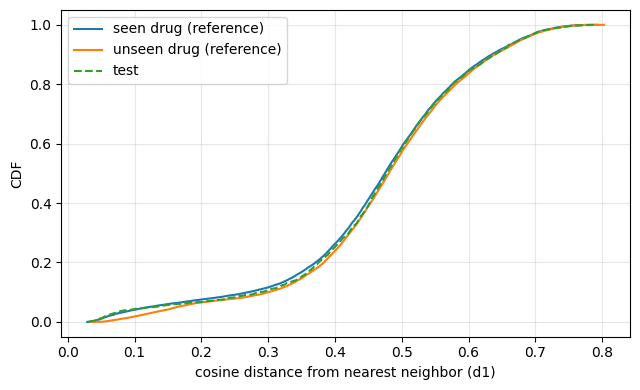

In [4]:
# Step 4 - are the two reference distributions separable? (method power)
labels = np.r_[np.zeros(len(seen_ref)), np.ones(len(unseen_ref))]
scores = np.r_[seen_ref["d1"].values, unseen_ref["d1"].values]
AUC = roc_auc_score(labels, scores)
qs = [0.05, 0.25, 0.50, 0.75, 0.95]
table = pd.DataFrame({"seen": np.quantile(seen_ref["d1"], qs), "unseen": np.quantile(unseen_ref["d1"], qs),
                      "test": np.quantile(test_ref["d1"], qs)}, index=[f"q{int(q * 100):02d}" for q in qs])
print("Quantiles of d1 (cosine distance from nearest neighbor):")
print(table.round(4).to_string())
print(f"\nAUC seen-vs-unseen on d1: {AUC:.3f}  (0.5 = no separation, 1.0 = perfect separation)")
if AUC < 0.65:
    print("WARNING: Low AUC. Nearest-neighbor distance does not separate seen and unseen drugs well: the estimate of p will be uninformative.")

fig, ax = plt.subplots(figsize=(6.5, 4))
for name, d, style in (("seen drug (reference)", seen_ref["d1"], "-"), ("unseen drug (reference)", unseen_ref["d1"], "-"), ("test", test_ref["d1"], "--")):
    x = np.sort(d.values); ax.plot(x, np.arange(1, len(x) + 1) / len(x), style, label=name)
ax.set_xlabel("cosine distance from nearest neighbor (d1)"); ax.set_ylabel("CDF"); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f"{OUTPUT_DIR}/nn_distance_ecdf.png", dpi=150); plt.show()


In [5]:
# Step 5 - estimation of p (proportion of test rows with a seen drug) via cluster bootstrap by drug
THRESHOLDS = np.quantile(np.r_[seen_ref["d1"].values, unseen_ref["d1"].values], np.linspace(0.02, 0.98, N_GRID))

def cdf_at(values, weights=None):
    indicator = (values[:, None] <= THRESHOLDS[None, :]).astype(np.float32)
    if weights is None:
        return indicator.mean(axis=0)
    return (weights @ indicator) / weights.sum(axis=1, keepdims=True)

def estimate_p(F_test, F_seen, F_unseen):
    """Least squares of F_test - F_unseen on F_seen - F_unseen (closed form, unconstrained p)."""
    a, b = F_seen - F_unseen, F_test - F_unseen
    return (a * b).sum(axis=-1) / (a * a).sum(axis=-1)

def cluster_weights(cluster_ids, n_boot):
    """Cluster bootstrap weights (by drug): rows belonging to the same drug are correlated."""
    _, dense = np.unique(cluster_ids, return_inverse=True)
    k = dense.max() + 1
    draws = rng.multinomial(k, np.full(k, 1.0 / k), size=n_boot).astype(np.float32)
    return draws[:, dense]

p_point = float(estimate_p(cdf_at(test_ref["d1"].values), cdf_at(seen_ref["d1"].values), cdf_at(unseen_ref["d1"].values)))
p_boot = estimate_p(cdf_at(test_ref["d1"].values, cluster_weights(np.arange(len(test_ref)), N_BOOT)),
                    cdf_at(seen_ref["d1"].values, cluster_weights(seen_ref["code"].values, N_BOOT)),
                    cdf_at(unseen_ref["d1"].values, cluster_weights(unseen_ref["code"].values, N_BOOT)))
p_low, p_high = np.percentile(p_boot, [2.5, 97.5])
print(f"Estimated p (proportion of test rows 'seen drug type'): {p_point:+.3f}  95% bootstrap CI [{p_low:+.3f}, {p_high:+.3f}]")
print("p < 0 or > 1: test set is further (or closer) than both references; the mixture does not describe it well.")


Estimated p (proportion of test rows 'seen drug type'): +0.506  95% bootstrap CI [-0.950, +2.072]
p < 0 or > 1: test set is further (or closer) than both references; the mixture does not describe it well.


In [6]:
# Step 6 - recovery check: does the method recover a known p with 3.6k rows? (pseudo-test)
def pseudo_test_check(p_values, hold_fold=N_FOLDS - 1):
    ref_s = seen_ref.loc[seen_ref["fold"] != hold_fold, "d1"].values
    ref_u = unseen_ref.loc[unseen_ref["fold"] != hold_fold, "d1"].values
    src_s = seen_ref.loc[seen_ref["fold"] == hold_fold, "d1"].values
    src_u = unseen_ref.loc[unseen_ref["fold"] == hold_fold, "d1"].values
    F_s, F_u = cdf_at(ref_s), cdf_at(ref_u)
    rows = []
    for p in p_values:
        n_s = int(round(p * n_test)); estimates = []
        for _ in range(N_PSEUDO_REPS):
            sample = np.r_[rng.choice(src_s, n_s, replace=len(src_s) < n_s), rng.choice(src_u, n_test - n_s, replace=len(src_u) < n_test - n_s)]
            estimates.append(float(estimate_p(cdf_at(sample), F_s, F_u)))
        rows.append({"true_p": p, "estimated_p_mean": np.mean(estimates), "sd": np.std(estimates),
                     "bias": np.mean(estimates) - p})
    return pd.DataFrame(rows)

recovery = pseudo_test_check([0.0, 0.05, 0.10, 0.25, 0.50, 1.0])
print(recovery.round(3).to_string(index=False))
print("\nPseudo-test and reference rows originate from different folds. A large SD or noticeable bias "
      "means that the real test estimate must be interpreted with the same uncertainty.")


 true_p  estimated_p_mean    sd  bias
   0.00             0.226 0.102 0.226
   0.05             0.347 0.137 0.297
   0.10             0.371 0.159 0.271
   0.25             0.468 0.168 0.218
   0.50             0.631 0.235 0.131
   1.00             1.058 0.116 0.058

Pseudo-test and reference rows originate from different folds. A large SD or noticeable bias means that the real test estimate must be interpreted with the same uncertainty.


In [7]:
# Step 7 - highly frequent drugs: how many test rows resemble each?
# "Assigned to X" = nearest neighbor in pool belongs to drug X AND distance is below threshold thr_X,
# the 90th percentile of d1 for actual drug X rows in row-wise reference.
def binom_rate(k, n, size):
    return rng.binomial(n, k / n, size=size) / n

rows = []
for X in frequent_codes:
    in_X = seen_ref["code"].values == X
    if in_X.sum() < 20:
        continue
    thr = np.quantile(seen_ref["d1"].values[in_X], 0.90)
    assigned_ref = (seen_ref["nn_code"].values == X) & (seen_ref["d1"].values <= thr)
    recall, fpr = assigned_ref[in_X].mean(), assigned_ref[~in_X].mean()
    assigned_test = (test_ref["nn_code"].values == X) & (test_ref["d1"].values <= thr)
    obs = int(assigned_test.sum())
    pi_train = rows_per_drug[X] / n_train
    pi_hat = (obs / n_test - fpr) / (recall - fpr)
    pi_boot = (binom_rate(obs, n_test, N_BOOT) - binom_rate(fpr * (~in_X).sum(), (~in_X).sum(), N_BOOT)) / \
              (binom_rate(recall * in_X.sum(), in_X.sum(), N_BOOT) - binom_rate(fpr * (~in_X).sum(), (~in_X).sum(), N_BOOT))
    lo, hi = np.percentile(pi_boot, [2.5, 97.5])
    rows.append({"drug": drug_names[X], "train_rows": int(rows_per_drug[X]), "train_share": pi_train,
                 "recall": recall, "fpr": fpr, "test_assigned": obs,
                 "expected_if_absent": fpr * n_test,
                 "expected_if_like_train": n_test * (pi_train * recall + (1 - pi_train) * fpr),
                 "estimated_test_share": pi_hat, "CI95_low": lo, "CI95_high": hi})
frequent_report = pd.DataFrame(rows).sort_values("train_rows", ascending=False)
print(frequent_report.round(4).to_string(index=False))
print("\nInterpretation: if 'test_assigned' is close to 'expected_if_absent', the drug is not in test; if it is close to "
      "'expected_if_like_train', it is present at train frequency. Intermediate values: partial presence or similar drugs (same mechanism).")
frequent_report.to_csv(f"{OUTPUT_DIR}/frequent_drugs_in_test.csv", index=False)


     drug  train_rows  train_share  recall    fpr  test_assigned  expected_if_absent  expected_if_like_train  estimated_test_share  CI95_low  CI95_high
87d714366         718       0.0327  0.8969 0.0015            133              5.3256                111.4871                0.0393    0.0322     0.0472
9f80f3f77         246       0.0112  0.6138 0.0111             46             40.3283                 64.8090                0.0026   -0.0036     0.0084
8b87a7a83         203       0.0092  0.8966 0.0001             23              0.5031                 30.5498                0.0069    0.0041     0.0098
5628cb3ee         202       0.0092  0.7030 0.0035             19             12.5769                 35.9079                0.0025   -0.0006     0.0062
d08af5d4b         196       0.0089  0.8214 0.0031             36             11.3999                 37.8820                0.0083    0.0046     0.0127
292ab2c28         194       0.0088  0.8505 0.0017             18              6.2023    

In [8]:
# Step 8 - summary
print("=" * 78)
print(f"AUC seen-vs-unseen: {AUC:.3f} | estimated p: {p_point:+.3f} [{p_low:+.3f}, {p_high:+.3f}]")
worst_bias = recovery["bias"].abs().max()
print(f"Maximum recovery error on pseudo-tests: {worst_bias:.3f}")
if AUC < 0.65:
    verdict = "UNINFORMATIVE: nearest neighbor distance does not sufficiently separate seen and unseen drugs."
elif p_high < 0.15:
    verdict = "consistent with a test set composed almost entirely of drugs NOT present in train."
elif p_low > 0.50:
    verdict = "consistent with a test set that shares many drugs with train."
else:
    verdict = "intermediate or inconclusive: interval includes both 'nearly all unseen' and substantial shares of seen drugs."
print("Verdict:", verdict)
n_present = int((frequent_report["test_assigned"] > 2 * frequent_report["expected_if_absent"] + 3).sum())
print(f"Frequent drugs with test assigned rows more than double the expected amount if absent (+3): {n_present} out of {len(frequent_report)}")
print("Remember: this is an indirect estimation. It does not prove the absence or presence of a specific drug.")


AUC seen-vs-unseen: 0.516 | estimated p: +0.506 [-0.950, +2.072]
Maximum recovery error on pseudo-tests: 0.297
Verdict: UNINFORMATIVE: nearest neighbor distance does not sufficiently separate seen and unseen drugs.
Frequent drugs with test assigned rows more than double the expected amount if absent (+3): 5 out of 8
Remember: this is an indirect estimation. It does not prove the absence or presence of a specific drug.
